In [ ]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

DATA_PATH = Path(
    "dataset-source/data/raw/messy_ecommerce_preprocessing.csv"
)

df_original = pd.read_csv(DATA_PATH)
df = df_original.copy(deep=True)

df.head()

,OrderID,CustomerName,ProductCategory,OrderDate,Quantity,UnitPrice,PaymentMethod,City
0,O1001,alice johnson,electronics,2025-01-05,2,49.99,credit card,chennai
1,O1002,BOB SMITH,HOME & KITCHEN,01/07/2025,1,$129.50,UPI,BENGALURU
2,O1003,Carla Diaz,electronics,2025-01-09 14:30:00,3,19.99,Debit Card,Mumbai
3,O1004,daniel lee,Books,31-01-2025,2,12.50,cash,Chennai
4,O1005,Eva Patel,Fashion,2025/02/03,4,24.99,credit card,Hyderabad


In [ ]:
print("Shape (rows, columns):", df.shape)
print("Columns:")
print(df.columns.tolist())

print("\nInfo:")
df.info()

# Descriptive statistics
df.describe(include="all").T

Shape (rows, columns): (51, 8)
Columns:
['OrderID', 'CustomerName', 'ProductCategory', 'OrderDate', 'Quantity', 'UnitPrice', 'PaymentMethod', 'City']

Info:
<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   OrderID          51 non-null     str  
 1   CustomerName     50 non-null     str  
 2   ProductCategory  51 non-null     str  
 3   OrderDate        50 non-null     str  
 4   Quantity         51 non-null     str  
 5   UnitPrice        51 non-null     str  
 6   PaymentMethod    51 non-null     str  
 7   City             51 non-null     str  
dtypes: str(8)
memory usage: 6.0 KB


,count,unique,top,freq
OrderID,51,50,O1015,2
CustomerName,50,49,Noah Wilson,2
ProductCategory,51,10,Electronics,14
OrderDate,50,49,2025-02-19,2
Quantity,51,7,1,28
UnitPrice,51,50,79.99,2
PaymentMethod,51,9,UPI,14
City,51,10,Chennai,14


In [ ]:
print("Missing values before cleaning:")
print(df.isna().sum().rename("missing_count").to_frame())

print("Duplicate rows:", df.duplicated().sum())
print(df[df.duplicated(keep=False)].sort_values("OrderID"))

Missing values before cleaning:
                 missing_count
OrderID                      0
CustomerName                 1
ProductCategory              0
OrderDate                    1
Quantity                     0
UnitPrice                    0
PaymentMethod                0
City                         0
Duplicate rows: 1
   OrderID CustomerName ProductCategory   OrderDate Quantity UnitPrice  \
14   O1015  Noah Wilson     Electronics  2025-02-19        1     79.99   
15   O1015  Noah Wilson     Electronics  2025-02-19        1     79.99   

   PaymentMethod   City  
14   Credit Card  Delhi  
15   Credit Card  Delhi  


In [ ]:
df_clean = df.copy(deep=True)

string_columns = [
    "OrderID",
    "CustomerName",
    "ProductCategory",
    "PaymentMethod",
    "City",
]
for col in string_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Consistent display casing for categorical/text fields
for col in ["CustomerName", "ProductCategory", "PaymentMethod", "City"]:
    df_clean[col] = df_clean[col].str.title()

# Normalize common missing-value placeholders before numeric/date parsing
missing_tokens = {"", "?", "--", "unknown", "nan", "nat", "none", "null"}
for col in string_columns:
    df_clean[col] = df_clean[col].mask(
        df_clean[col].str.casefold().isin(missing_tokens), pd.NA
    )

df_clean.head(10)

,OrderID,CustomerName,ProductCategory,OrderDate,Quantity,UnitPrice,PaymentMethod,City
0,O1001,Alice Johnson,Electronics,2025-01-05,2,49.99,Credit Card,Chennai
1,O1002,Bob Smith,Home & Kitchen,01/07/2025,1,$129.50,Upi,Bengaluru
2,O1003,Carla Diaz,Electronics,2025-01-09 14:30:00,3,19.99,Debit Card,Mumbai
3,O1004,Daniel Lee,Books,31-01-2025,2,12.50,Cash,Chennai
4,O1005,Eva Patel,Fashion,2025/02/03,4,24.99,Credit Card,Hyderabad
5,O1006,Frank Miller,Electronics,not-a-date,1,899.99,Credit Card,Pune
6,O1007,Grace Chen,Home & Kitchen,2025-02-08,two,35.00,Upi,Kolkata
7,O1008,Henry Adams,Books,2025-02-10,2,unknown,Cash,Jaipur
8,O1009,<NA>,Fashion,2025-02-11,1,59.00,Debit Card,Delhi
9,O1010,Isabel Martin,Electronics,2025-02-12,5,-10.00,Upi,Chennai


In [ ]:
duplicates_before = df_clean.duplicated().sum()
df_nodup = df_clean.drop_duplicates()

print("Duplicate rows removed:", duplicates_before)
print("Shape after duplicate removal:", df_nodup.shape)

Duplicate rows removed: 1
Shape after duplicate removal: (50, 8)


In [ ]:
# Date parsing
df_nodup["OrderDate"] = pd.to_datetime(
    df_nodup["OrderDate"], errors="coerce", format="mixed"
).dt.strftime("%Y-%m-%d")

# Currency formatting
price_text = (
    df_nodup["UnitPrice"]
    .astype("string")
    .str.strip()
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .replace(["", "--", "unknown", "Unknown", "?", "nan"], pd.NA)
)
df_nodup["UnitPrice"] = pd.to_numeric(price_text, errors="coerce")

quantity_text = (
    df_nodup["Quantity"]
    .astype("string")
    .str.strip()
    .replace(["", "--", "unknown", "Unknown", "?", "nan"], pd.NA)
)
df_nodup["Quantity"] = pd.to_numeric(quantity_text, errors="coerce")

print(df_nodup[["OrderDate", "Quantity", "UnitPrice"]].dtypes)
df_nodup[["OrderID", "OrderDate", "Quantity", "UnitPrice"]].head(12)

OrderDate        str
Quantity       Int64
UnitPrice    Float64
dtype: object


,OrderID,OrderDate,Quantity,UnitPrice
0,O1001,2025-01-05,2,49.99
1,O1002,2025-01-07,1,129.5
2,O1003,2025-01-09,3,19.99
3,O1004,2025-01-31,2,12.5
4,O1005,2025-02-03,4,24.99
...,...,...,...,...
7,O1008,2025-02-10,2,<NA>
8,O1009,2025-02-11,1,59.0
9,O1010,2025-02-12,5,-10.0
10,O1011,2025-02-14,0,15.0


In [ ]:
print("Missing values after parsing:")
print(df_nodup.isna().sum().rename("missing_count").to_frame())
print()

print("Non-positive unit prices:")
print(df_nodup.loc[df_nodup["UnitPrice"].le(0), ["OrderID", "UnitPrice"]])
print()

print("Non-positive quantities:")
print(df_nodup.loc[df_nodup["Quantity"].le(0), ["OrderID", "Quantity"]])
print()

print("Dtypes after conversion:")
print(df_nodup.dtypes.rename("dtype").to_frame())

Missing values after parsing:
                 missing_count
OrderID                      0
CustomerName                 1
ProductCategory              0
OrderDate                    3
Quantity                     1
UnitPrice                    1
PaymentMethod                0
City                         0

Non-positive unit prices:
   OrderID  UnitPrice
9    O1010      -10.0
22   O1022        0.0

Non-positive quantities:
   OrderID  Quantity
10   O1011         0

Dtypes after conversion:
                   dtype
OrderID           string
CustomerName      string
ProductCategory   string
OrderDate            str
Quantity           Int64
UnitPrice        Float64
PaymentMethod     string
City              string


In [ ]:
invalid_price_mask = df_nodup["UnitPrice"].le(0)
invalid_quantity_mask = df_nodup["Quantity"].le(0)

df_nodup["InvalidPriceFlag"] = invalid_price_mask.fillna(False)
df_nodup["InvalidQuantityFlag"] = invalid_quantity_mask.fillna(False)

df_nodup.loc[invalid_price_mask, "UnitPrice"] = np.nan
df_nodup.loc[invalid_quantity_mask, "Quantity"] = np.nan

print("Invalid prices flagged:", df_nodup["InvalidPriceFlag"].sum())
print("Invalid quantities flagged:", df_nodup["InvalidQuantityFlag"].sum())

Invalid prices flagged: 2
Invalid quantities flagged: 1


In [ ]:
# Ivalid prices and quantities
df_invalid = df_nodup[
    ["UnitPrice", "InvalidPriceFlag", "Quantity", "InvalidQuantityFlag"]
]

df_invalid[
    (df_invalid["InvalidPriceFlag"] == True)
    | (df_invalid["InvalidQuantityFlag"] == True)
]

,UnitPrice,InvalidPriceFlag,Quantity,InvalidQuantityFlag
9,<NA>,True,5,False
10,15.0,False,<NA>,True
22,<NA>,True,2,False


In [ ]:
price = df_nodup["UnitPrice"].dropna()
Q1 = price.quantile(0.25)
Q3 = price.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")

outlier_mask = df_nodup["UnitPrice"].lt(lower_bound) | df_nodup[
    "UnitPrice"
].gt(upper_bound)
df_nodup["PriceOutlierFlag"] = outlier_mask.fillna(False)

df_nodup.loc[
    df_nodup["PriceOutlierFlag"],
    ["OrderID", "ProductCategory", "UnitPrice", "Quantity"],
].sort_values("UnitPrice")

Q1: 24.99
Q3: 72.50
IQR: 47.51
Lower bound: -46.26
Upper bound: 143.76


,OrderID,ProductCategory,UnitPrice,Quantity
5,O1006,Electronics,899.99,1
12,O1013,Electronics,2500.0,1
18,O1018,Fashion,9999.0,1


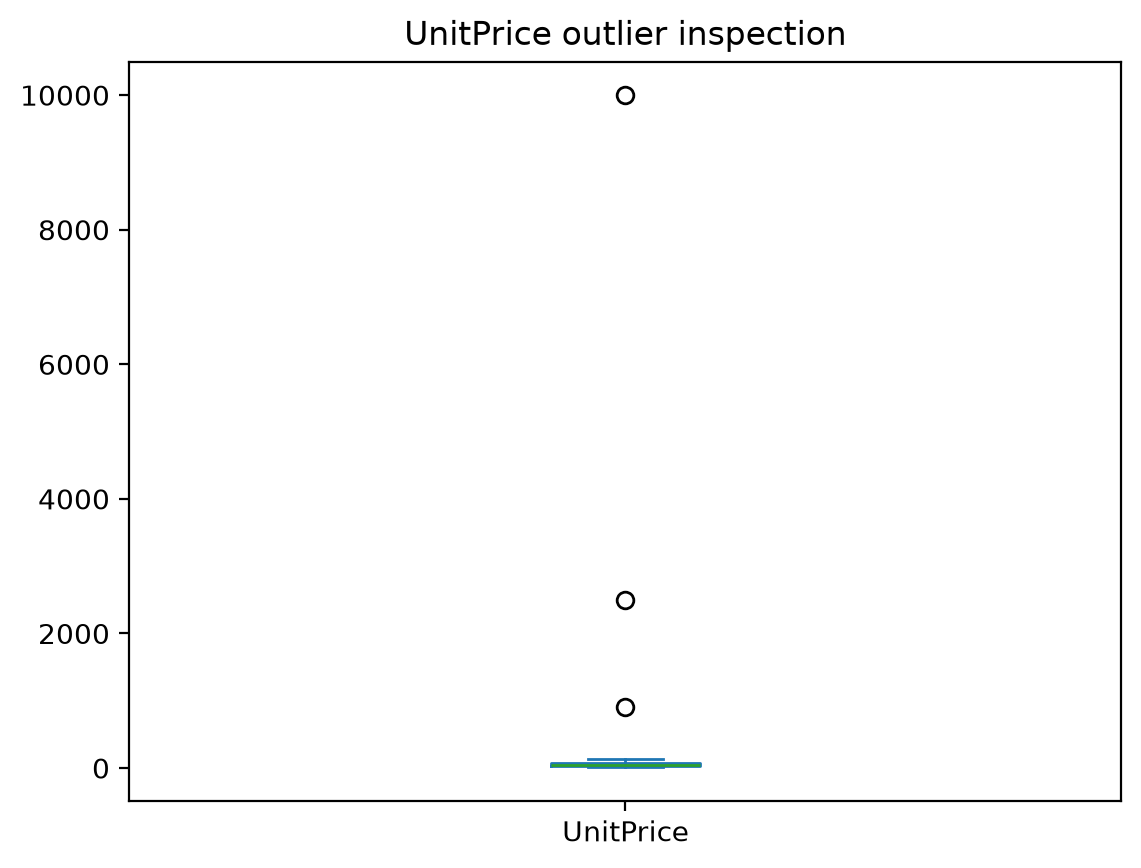

In [ ]:
# Box plot for visual validation
df_nodup[["UnitPrice"]].plot(
    kind="box", vert=True, title="UnitPrice outlier inspection"
)

In [ ]:
# Total amount is unknown when either quantity or unit price is missing.
df_nodup["TotalAmount"] = df_nodup["Quantity"] * df_nodup["UnitPrice"]

def categorize_price(price):
    if pd.isna(price):
        return "Unknown"
    if price < 25:
        return "Low"
    if price < 100:
        return "Medium"
    return "High"

df_nodup["PriceCategory"] = df_nodup["UnitPrice"].apply(categorize_price)

df_nodup[
    ["OrderID", "Quantity", "UnitPrice", "TotalAmount", "PriceCategory"]
].head(15)

,OrderID,Quantity,UnitPrice,TotalAmount,PriceCategory
0,O1001,2,49.99,99.98,Medium
1,O1002,1,129.5,129.5,High
2,O1003,3,19.99,59.97,Low
3,O1004,2,12.5,25.0,Low
4,O1005,4,24.99,99.96,Low
...,...,...,...,...,...
10,O1011,<NA>,15.0,<NA>,Low
11,O1012,2,25.0,50.0,Medium
12,O1013,1,2500.0,2500.0,High
13,O1014,3,39.99,119.97,Medium


In [ ]:
print("Category counts:")
df_nodup["ProductCategory"].value_counts(dropna=False)

Category counts:


,count
ProductCategory,
Electronics,16
Fashion,13
Books,11
Home & Kitchen,10


In [ ]:
print("Revenue by category (missing totals are skipped):")
df_nodup.groupby("ProductCategory", dropna=False)["TotalAmount"].sum(
    min_count=1
).sort_values(ascending=False).rename("Revenue").to_frame()

Revenue by category (missing totals are skipped):


,Revenue
ProductCategory,
Fashion,10874.93
Electronics,4573.93
Home & Kitchen,520.5
Books,266.0


In [ ]:
print("Orders with medium/high unit prices:")
df_nodup.loc[
    df_nodup["PriceCategory"].isin(["Medium", "High"]),
    ["OrderID", "ProductCategory", "UnitPrice", "PriceCategory"],
]

Orders with medium/high unit prices:


,OrderID,ProductCategory,UnitPrice,PriceCategory
0,O1001,Electronics,49.99,Medium
1,O1002,Home & Kitchen,129.5,High
5,O1006,Electronics,899.99,High
6,O1007,Home & Kitchen,35.0,Medium
8,O1009,Fashion,59.0,Medium
...,...,...,...,...
45,O1045,Electronics,85.0,Medium
46,O1046,Fashion,42.0,Medium
47,O1047,Home & Kitchen,33.0,Medium
48,O1048,Electronics,92.0,Medium


In [ ]:
df_final = df_nodup.copy(deep=True)
# Data validation
print("Final shape:", df_final.shape)
print("\nMissing values:")
print(df_final.isna().sum().rename("missing_count").to_frame())

print("Exact duplicate rows:", df_clean.duplicated().sum())
print("\nDtypes:")
print(df_final.dtypes.rename("dtype").to_frame())

print("Remaining non-positive prices:", df_final["UnitPrice"].le(0).sum())
print(
    "Remaining non-positive quantities:", df_final["Quantity"].le(0).sum()
)

# Derived-column checks
expected_total = df_final["Quantity"] * df_final["UnitPrice"]
totals_match = np.isclose(
    df_final["TotalAmount"].fillna(-999),
    expected_total.fillna(-999),
    equal_nan=False,
).all()
print("TotalAmount matches Quantity × UnitPrice:", totals_match)

expected_categories = df_final["UnitPrice"].apply(categorize_price)
print(
    "PriceCategory matches rule:",
    df_final["PriceCategory"].equals(expected_categories),
)

df_final.head(10)

Final shape: (50, 13)

Missing values:
                     missing_count
OrderID                          0
CustomerName                     1
ProductCategory                  0
OrderDate                        3
Quantity                         2
...                            ...
InvalidPriceFlag                 0
InvalidQuantityFlag              0
PriceOutlierFlag                 0
TotalAmount                      5
PriceCategory                    0

[13 rows x 1 columns]
Exact duplicate rows: 1

Dtypes:
                       dtype
OrderID               string
CustomerName          string
ProductCategory       string
OrderDate                str
Quantity               Int64
...                      ...
InvalidPriceFlag     boolean
InvalidQuantityFlag  boolean
PriceOutlierFlag     boolean
TotalAmount          Float64
PriceCategory            str

[13 rows x 1 columns]
Remaining non-positive prices: 0
Remaining non-positive quantities: 0
TotalAmount matches Quantity × UnitPrice: Tr

,OrderID,CustomerName,ProductCategory,OrderDate,Quantity,UnitPrice,PaymentMethod,City,InvalidPriceFlag,InvalidQuantityFlag,PriceOutlierFlag,TotalAmount,PriceCategory
0,O1001,Alice Johnson,Electronics,2025-01-05,2,49.99,Credit Card,Chennai,False,False,False,99.98,Medium
1,O1002,Bob Smith,Home & Kitchen,2025-01-07,1,129.5,Upi,Bengaluru,False,False,False,129.5,High
2,O1003,Carla Diaz,Electronics,2025-01-09,3,19.99,Debit Card,Mumbai,False,False,False,59.97,Low
3,O1004,Daniel Lee,Books,2025-01-31,2,12.5,Cash,Chennai,False,False,False,25.0,Low
4,O1005,Eva Patel,Fashion,2025-02-03,4,24.99,Credit Card,Hyderabad,False,False,False,99.96,Low
5,O1006,Frank Miller,Electronics,NaN,1,899.99,Credit Card,Pune,False,False,True,899.99,High
6,O1007,Grace Chen,Home & Kitchen,2025-02-08,<NA>,35.0,Upi,Kolkata,False,False,False,<NA>,Medium
7,O1008,Henry Adams,Books,2025-02-10,2,<NA>,Cash,Jaipur,False,False,False,<NA>,Unknown
8,O1009,<NA>,Fashion,2025-02-11,1,59.0,Debit Card,Delhi,False,False,False,59.0,Medium
9,O1010,Isabel Martin,Electronics,2025-02-12,5,<NA>,Upi,Chennai,True,False,False,<NA>,Unknown


In [ ]:
# Comparison with the og data
print("Original shape:", df_original.shape)
print("Cleaned shape:", df_final.shape)
print(
    "Rows removed as exact duplicates:", len(df) - len(df.drop_duplicates())
)

# Compare selected fields by original row index where possible.
comparison_columns = [
    "OrderID",
    "CustomerName",
    "ProductCategory",
    "OrderDate",
    "Quantity",
    "UnitPrice",
    "PaymentMethod",
    "City",
]
raw_aligned = df_original[comparison_columns].copy()
clean_aligned = df_final.reindex(columns=comparison_columns).copy()

print("Original sample:")
print(raw_aligned.head(10))
print("Cleaned sample:")
print(clean_aligned.head(10))

Original shape: (51, 8)
Cleaned shape: (50, 13)
Rows removed as exact duplicates: 1
Original sample:
   OrderID     CustomerName ProductCategory            OrderDate Quantity  \
0   O1001    alice johnson     electronics            2025-01-05        2   
1    O1002        BOB SMITH  HOME & KITCHEN           01/07/2025        1   
2    O1003       Carla Diaz     electronics  2025-01-09 14:30:00        3   
3    O1004       daniel lee          Books            31-01-2025        2   
4    O1005        Eva Patel         Fashion           2025/02/03        4   
5    O1006    Frank Miller      electronics           not-a-date        1   
6    O1007       Grace Chen  Home & Kitchen           2025-02-08      two   
7    O1008      Henry Adams           Books           2025-02-10        2   
8    O1009              NaN         fashion           2025-02-11        1   
9    O1010    Isabel Martin     Electronics           2025-02-12        5   

  UnitPrice  PaymentMethod       City  
0     49.99